In [1]:
import numpy as np
import pandas as pd
from datetime import datetime, timedelta
import matplotlib.pyplot as plt

# Set random seed for reproducibility
np.random.seed(42)

In [2]:
# Parameters for Karachi's climate
BASE_TEMP = 85  # Base engine temperature in °C
DAILY_VARIATION = 12  # Daily temperature variation
YEARLY_VARIATION = 8  # Yearly temperature variation
TREND = 0.018  # Slightly increased aging trend
NOISE_LEVEL = 1.7  # Random noise level

In [3]:
# Generate date range for 2024 (leap year)
start_date = datetime(2024, 1, 1)
end_date = datetime(2024, 12, 31)
dates = pd.date_range(start_date, end_date, freq='H')

C:\Users\PMLS\AppData\Local\Temp\ipykernel_94360\178974534.py:4: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  dates = pd.date_range(start_date, end_date, freq='H')


In [4]:
df = pd.DataFrame(index=dates)
df['datetime'] = df.index

In [5]:
# Yearly seasonality adjusted for leap year
def yearly_seasonality(date):
    day_of_year = date.timetuple().tm_yday
    return np.sin(2 * np.pi * day_of_year / 366) * YEARLY_VARIATION  # 366 for leap year

# Daily seasonality (more intense afternoon heat)
def daily_seasonality(date):
    hour = date.hour
    return -np.cos(2 * np.pi * (hour - 14) / 24) * DAILY_VARIATION  # Peak at 2 PM

# Weekly pattern updated for 2024 calendar
def weekly_pattern(date):
    if date.weekday() < 4:  # Monday-Thursday
        return 2.8
    elif date.weekday() == 4:  # Friday
        return 2.0  # Reduced traffic due to Friday prayers
    else:  # Weekend
        return -1.5

# Random spikes with monsoon consideration
def random_spikes(n):
    spikes = np.zeros(n)
    for i in range(n):
        if np.random.rand() < 0.005:
            spikes[i] = np.random.uniform(5, 15)  # Heat spikes
        elif np.random.rand() < 0.003:  # Cooling effects
            spikes[i] = np.random.uniform(-8, -4)  # Monsoon cooling
    return spikes

In [6]:
# Generate components
n = len(df)
time = np.arange(n)

# Base temperature with yearly trend
yearly_comp = np.array([yearly_seasonality(date) for date in df.index])
daily_comp = np.array([daily_seasonality(date) for date in df.index])
weekly_comp = np.array([weekly_pattern(date) for date in df.index])
spikes = random_spikes(n)
trend = TREND * time / 24  # Hourly trend
noise = np.random.normal(0, NOISE_LEVEL, n)

In [7]:
# Combine all components
temperature = (BASE_TEMP + yearly_comp + daily_comp + weekly_comp + 
              spikes + trend + noise)

# Clip values to realistic range (70°C-125°C) with emergency overheat
temperature = np.clip(temperature, 70, 130)

In [8]:
# Add to dataframe
df['Engine_Temperature'] = temperature.round(1)

# Add contextual columns
df['Hour'] = df.index.hour
df['DayOfWeek'] = df.index.dayofweek
df['Month'] = df.index.month
df['IsWeekend'] = df['DayOfWeek'].isin([5, 6]).astype(int)
df['IsRushHour'] = ((df['Hour'].between(7, 10)) | (df['Hour'].between(17, 21))).astype(int)

In [9]:
heat_wave_2024 = [datetime(2024, 5, d) for d in range(15, 25)] + \
                 [datetime(2024, 6, d) for d in range(5, 18)]

# Monsoon cooling days
monsoon_days = [datetime(2024, 7, d) for d in range(10, 20)] + \
               [datetime(2024, 8, d) for d in range(5, 15)]

for date in heat_wave_2024:
    df.loc[df.index.date == date.date(), 'Engine_Temperature'] += np.random.uniform(4, 9)

for date in monsoon_days:
    df.loc[df.index.date == date.date(), 'Engine_Temperature'] += np.random.uniform(-6, -3)

In [10]:
df.head()

,datetime,Engine_Temperature,Hour,DayOfWeek,Month,IsWeekend,IsRushHour
2024-01-01 00:00:00,2024-01-01 00:00:00,101.4,0,0,1,0,0
2024-01-01 01:00:00,2024-01-01 01:00:00,98.9,1,0,1,0,0
2024-01-01 02:00:00,2024-01-01 02:00:00,99.9,2,0,1,0,0
2024-01-01 03:00:00,2024-01-01 03:00:00,102.0,3,0,1,0,0
2024-01-01 04:00:00,2024-01-01 04:00:00,98.6,4,0,1,0,0


In [11]:
df.drop(columns=[
"Hour",
"DayOfWeek",
"Month",
"IsWeekend",
"IsRushHour"], inplace=True)

In [12]:
df.head()

,datetime,Engine_Temperature
2024-01-01 00:00:00,2024-01-01 00:00:00,101.4
2024-01-01 01:00:00,2024-01-01 01:00:00,98.9
2024-01-01 02:00:00,2024-01-01 02:00:00,99.9
2024-01-01 03:00:00,2024-01-01 03:00:00,102.0
2024-01-01 04:00:00,2024-01-01 04:00:00,98.6


In [13]:
# Reset index and save to CSV
df.reset_index(drop=True, inplace=True)
df.to_csv('karachi_2024_vehicle_temperature_data.csv', index=False)

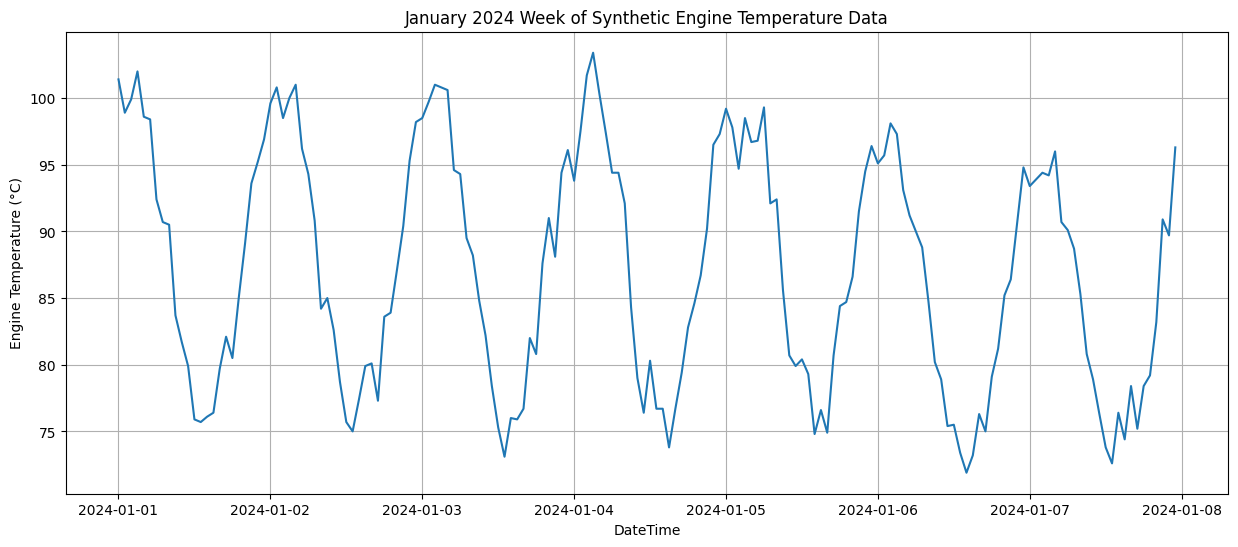

In [14]:
plt.figure(figsize=(15, 6))
plt.plot(df['datetime'][:24*7], df['Engine_Temperature'][:24*7])
plt.title('January 2024 Week of Synthetic Engine Temperature Data')
plt.xlabel('DateTime')
plt.ylabel('Engine Temperature (°C)')
plt.grid(True)
plt.show()

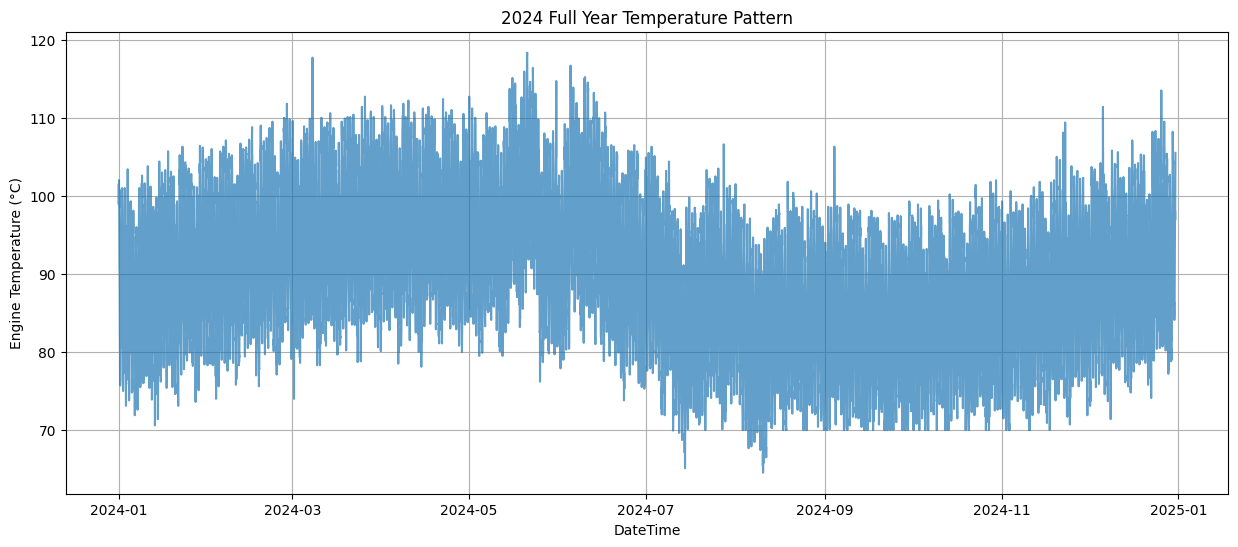

In [15]:
plt.figure(figsize=(15, 6))
plt.plot(df['datetime'], df['Engine_Temperature'], alpha=0.7)
plt.title('2024 Full Year Temperature Pattern')
plt.xlabel('DateTime')
plt.ylabel('Engine Temperature (°C)')
plt.grid(True)
plt.show()